# Which workloads hurt Frontier the most, and what would help?

This notebook uses the fitted model from `frontier_cooling_group.ipynb` to answer five questions. The answers come first. The rest of the notebook shows how each one was reached.

**1. Which workloads are worst for the cooling system?**
All 3 cabinets swinging together between idle and full power, about every **10 minutes**. The supply water then runs 2.5 °C off target on average and up to 5.5 °C off at the worst moment, and the valve moves the most. Any single big start or stop reaches about 6.4 °C off target. Keeping the cabinets out of step nearly removes the problem.

**2. Which workloads are worst for the chip?**
It depends on what is wearing out, because there are three different kinds of damage:

| Kind of damage | What it's like | Worst workload here |
|---|---|---|
| **Heat wear** (slow chemistry, e.g. electromigration) | Rust: hotter means faster | **Steady full power**, with no breaks to cool down |
| **Fatigue of soft metal** (solder) | Bending a paperclip: small bends add up | **Rapid on/off every ~2–10 s**, *if* small swings do damage |
| **Cracking of brittle layers** | A cold glass in hot water: only big shocks count | **Synchronized swings every ~5–10 min**, the same ones that are worst for the cooling |

If you want one worst case, it is **big, synchronized power swings every several minutes**. It comes first or close to first for the cooling system and for cracking, and it gives the chip its biggest temperature swings, because the cooling system's lag adds about 9 °C to the ~21 °C swing the chip makes on its own.

**3. What decisions could improve chip lifetime?**
The biggest gains are cheap ones. **Letting the CDU valve also watch cabinet power** (feed-forward) cuts the supply overshoot from 5.5 to 1.2 °C and fatigue damage by about 60 %, and needs no new plumbing. **Staggering cabinets in the scheduler** does about the same. Better paste helps with both fatigue and heat. A bigger heat exchanger or a wider valve range alone does almost nothing.

**4. What happens to chip expansion and contraction?**
The movements are tiny but repeat with every swing. At the corner of a die in a 30 °C swing, the silicon moves about 1.5 µm and the copper cold plate about 4.9 µm, so the paste between them gets dragged back and forth by about **3.5 µm**. Coolant swings are the surprise: per degree of chip temperature, warmer *coolant* drags the paste about 7 times more than the chip's own heating does. So cooling lag matters more for paste wear than for anything else here.

**5. Does the model work for one GPU on a cold plate with variable flow?**
Yes, with one assumed piece. Near the fitted flow, changing flow barely matters: only about a sixth of the chip-to-water resistance depends on flow at all.

**6. The simple function** is the last code cell: `predict_cooling(cabinet_power_kW)`.

### How far to trust this

* **Measured and checked:** the cooling group's response to one real HPL run, and one GPU's temperature.
* **Modelled, not measured:** every other workload here. Nobody ran them on Frontier.
* **Comparisons, not lifetimes:** nothing here predicts "this GPU lasts 6 years". AMD doesn't publish the needed numbers. The fatigue constants come from solder studies on other packages. Read "3× the damage" as a comparison between workloads under stated assumptions.

In [1]:
import re, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

from ampere import Ensemble, MetricConfig, MetricType, set_backend
set_backend('pandas')

ROOT = Path('.').resolve(); sys.path.insert(0, str(ROOT))
import frontier_model as fm

FIG = ROOT / 'figures'; OUT = ROOT / 'results'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
POWER_C, MAIN_C, CMP_C, THIRD_C = '0.45', 'tab:blue', 'tab:orange', 'tab:green'

M = fm.load_model()                                           # the fitted model from frontier_cooling_group.ipynb
rms = lambda r: float(np.sqrt(np.mean(np.square(r))))

# The measured 3-cabinet run, used to set realistic power levels and to re-check the model
raw = pd.read_csv(ROOT / '3Cab_POW.txt', sep=r'\s+', skiprows=11)
t_raw = (pd.to_datetime(raw.TS) - pd.to_datetime(raw.TS.iloc[0])).dt.total_seconds().to_numpy()
t_cg = np.arange(0.0, np.floor(t_raw[-1]) + 1)
col = lambda c: np.interp(t_cg, t_raw, raw[c].to_numpy(float))
AC_M = np.array([col(f'ACP_C{i}') for i in (1, 2, 3)]); RF_M = np.array([col(f'RFNP_C{i}') for i in (1, 2, 3)])
LIT_M = np.mean([col(f'LIT_C{i}') for i in (1, 2, 3)], 0); PLF_M, PIT_M = col('CDU_PLF'), col('CDU_PIT')

NODE_LO = RF_M[:, t_cg > 2200].mean() / fm.N_NODES            # measured idle, W per node
NODE_HI = RF_M.max(1).mean() / fm.N_NODES                     # measured HPL peak, W per node
NODE_SOLO = 2692.0                                            # the single-node rocHPL run's level, above anything measured on a whole cabinet
PIT0 = PIT_M.mean()
T_SET = M['ctl']['T_set']
chk = fm.run_cooling(M, AC_M, PIT_M); late = t_cg > 300
print(f"model re-check on the measured run, after t = 300 s: supply off by {rms((chk['LIT'] - LIT_M)[late]):.2f} K, valve flow off by {rms((chk['PLF'] - PLF_M)[late]):.1f} gpm")
print(f"power levels: idle {NODE_LO:.0f} W/node ({fm.package_from_node(M, NODE_LO):.0f} W per GPU), "
      f"peak {NODE_HI:.0f} W/node ({fm.package_from_node(M, NODE_HI):.0f} W per GPU)")

# The HPL stall pattern of one real GPU, from the single-node rocHPL trace
configs = {re.compile(r".*rocm_smi.*energy.*"): MetricConfig(MetricType.CUMULATIVE, scale_factor=1e-6)}
node = Ensemble.from_trace_paths([str(ROOT / 'data' / 'rochpl-frontier')], {"Node0": ["MPI Rank 0"]}, configs).runs[0].nodes[0]
rank0 = node.ranks[0]
names = np.asarray(rank0.names.to_ndarray()).astype(str); i_g = np.flatnonzero(np.char.startswith(names, 'HPL_pdgesv'))[0]
T_G0, T_G1 = np.asarray(rank0.starts.to_ndarray())[i_g], np.asarray(rank0.ends.to_ndarray())[i_g]
e = node.metrics["A2rocm_smi:::energy_count:device=0"]; t_e = np.asarray(e.times.to_ndarray(), float); E_J = np.asarray(e.values.to_ndarray(), float)
DT_W = 0.01; PER = int(round(1 / DT_W))                       # workloads use a 10 ms grid, fine for the die's ~30 ms time constant
g = np.arange(T_G0 + 8, T_G1 - 8, DT_W)
p_hpl = np.diff(np.interp(np.r_[g, g[-1] + DT_W], t_e, E_J)) / DT_W
FINE = p_hpl / uniform_filter1d(p_hpl, 2 * PER, mode='wrap')  # power relative to its own 2 s average (mean about 1)
print(f"HPL pattern: {len(FINE) * DT_W:.0f} s long; goes from {FINE.min():.2f} to {FINE.max():.2f} times its local average")

    _         _                   _       
   / \   _ __| | _____  _   _  __| | __ _ 
  / _ \ | '__| |/ / _ \| | | |/ _` |/ _` |
 / ___ \| |  |   < (_) | |_| | (_| | (_| |
/_/   \_\_|  |_|\_\___/ \__,_|\__,_|\__,_|
                                          
Client Version: 2026.02.02+40.gec39a6ec8

model re-check on the measured run, after t = 300 s: supply off by 0.44 K, valve flow off by 5.3 gpm
power levels: idle 477 W/node (72 W per GPU), peak 2221 W/node (451 W per GPU)



Loading Runs:   0%|          | 0/1 [00:00<?, ?it/s]


Loading Runs: 100%|██████████| 1/1 [00:01<00:00,  1.12s/it]


Loading Runs: 100%|██████████| 1/1 [00:01<00:00,  1.12s/it]

HPL pattern: 47 s long; goes from 0.28 to 1.27 times its local average


## Part 1: Run a catalogue of workloads and score them

The cell above loaded the model, re-checked it against the real run (it stays within about 0.4 °C on the supply water), and read the real stall pattern from the rocHPL trace.

**The workloads.** Each one runs on the model for 2 hours. The first hour lets it settle, and the second hour is scored. Power swings between the **idle** (477 W per node) and **peak** (2221 W per node) levels measured on these cabinets. Two entries marked with `*` use the higher 2692 W per node of the single-node run, which is outside what these cabinets were measured doing, so treat them as extrapolations.

Only HPL's real pattern comes from measurement. The other shapes are made up on purpose, to find out which rhythm does the most harm.

**The scores for the chip** (at the hottest GPU):

| Score | Meaning |
|---|---|
| `Tj_max`, `Tj_swing` | Hottest junction temperature, and the biggest swing from hot to cool |
| `cycles_per_h` | How many times per hour the chip heats and cools by 2 °C or more. Counted by *rainflow*, the standard way to count fatigue cycles: it pairs each heat-up with its matching cool-down, even when small loops sit inside big ones |
| `dmg_265`, `dmg_4`, `dmg_6` | **Fatigue damage per hour**, relative to the 40-minute job. Each cycle counts as $\Delta T^{\,n}\, f^{-0.136}\, e^{-2185/T_{peak}}$: bigger swings count much more, slower cycles a bit more, hotter cycles a bit more (the Norris–Landzberg form; constants from the SAC solder fit [1]) |
| `dmg_265_all`, `dmg_265_10K` | The same, but counting swings as small as 0.25 °C, or ignoring anything below 10 °C. This tests the assumption that very small swings are harmless |
| `wear` | **Heat wear rate**: average of the Arrhenius factor with 0.9 eV (typical for copper electromigration [2]), where 1 means always at 60 °C. Near 60 °C, each 1 °C changes it by about 10 % |

**What $n$ means.** It is the damage exponent, and it sets how much big swings count relative to small ones. Doubling a swing multiplies the damage per cycle by $2^n$: 6× for $n$ = 2.65, 64× for $n$ = 6. Soft solder has a low $n$; brittle layers have a high one. I use 2.65 (the SAC solder fit [1]), with 4 and 6 as what-if values for harder and more brittle materials. No one has published $n$ for the MI250X, which is why the answer is given for all three.

**The scores for the cooling system:** how far the supply water is off target (worst moment and average), the hottest cabinet outlet, how fast the outlet temperature changes, how much the valve moves (total travel, ignoring moves under 1 gpm), and how long it sits against the end of its range.

In [2]:
HOURS = 2.0
N_W = int(HOURS * 3600 / DT_W); T_W = np.arange(N_W) * DT_W
DROP_S = 3600.0                                              # the first hour lets things settle; scores use the second hour

def square(period, duty=0.5, hi=NODE_HI, lo=NODE_LO, phase=0.0, t=T_W):
    '''Per-node power switching between hi and lo: busy for duty * period, then idle, repeating.'''
    return np.where(((t - phase) % period) < duty * period, hi, lo)

def soft(x, ramp_s):
    '''The same power with every jump spread over ramp_s seconds (a scheduler "soft start").'''
    return uniform_filter1d(x, int(ramp_s / DT_W), mode='nearest')

def churn(seed, lo_min=2, hi_min=30):
    '''Jobs starting and stopping at random: busy or idle stretches of random length, lo_min to hi_min minutes.'''
    r = np.random.default_rng(seed); out = np.empty(N_W); i = 0; on = True
    while i < N_W:
        n = int(r.uniform(lo_min, hi_min) * 60 / DT_W); out[i:i + n] = NODE_HI if on else NODE_LO; i += n; on = not on
    return out

def stalls(period=1.4, stall=0.1):
    '''Full power with a short drop to idle every `period` seconds (the shape of an HPL panel stall, made regular).'''
    return np.where((T_W % period) < stall, NODE_LO, NODE_HI)

same = lambda x: np.tile(x, (3, 1))
HPL_NODE = np.interp(T_W, t_cg, RF_M[0] / fm.N_NODES)        # the measured run, for its 47 min; idle afterwards
HPL_NODE[T_W > t_cg[-1]] = NODE_LO
WORKLOADS = {                                     # name: (per-node power for each of 3 cabinets, add the real HPL pattern?)
    'Steady full power':                 (same(np.full(N_W, NODE_HI)), False),
    'Steady full power + HPL stalls':    (same(np.full(N_W, NODE_HI)), True),
    'Regular 100 ms stalls every 1.4 s': (same(stalls()), False),
    'On/off every 2 s':                  (same(square(2)), False),
    'On/off every 10 s':                 (same(square(10)), False),
    'On/off every 1 min':                (same(square(60)), False),
    'On/off every 5 min':                (same(square(300)), False),
    'On/off every 10 min':               (same(square(600)), False),
    'On/off every 30 min':               (same(square(1800)), False),
    'Long job: 40 min on, 20 off':       (same(square(3600, 2 / 3)), False),
    'Random job churn, all cabinets':    (same(churn(1)), False),
    'Random job churn, separate cabinets': (np.array([churn(1), churn(2), churn(3)]), False),
    'On/off every 10 min, soft start':   (same(soft(square(600), 180)), False),
    'On/off every 10 min, staggered':    (np.array([square(600, phase=200 * j) for j in range(3)]), False),
    'On/off every 10 min, 1 cabinet':    (np.array([square(600), np.full(N_W, NODE_LO), np.full(N_W, NODE_LO)]), False),
    'Steady, single-node power level*':  (same(np.full(N_W, NODE_SOLO)), False),
    'On/off every 10 min, single-node level*': (same(square(600, hi=NODE_SOLO)), False),
}

def gpu_power(node_W, with_stalls, package_fine=FINE):
    '''One GPU's power [W] from its node's power, optionally with the real HPL pattern added while busy.'''
    p = fm.package_from_node(M, node_W)
    if not with_stalls:
        return p
    lo, hi = fm.package_from_node(M, NODE_LO), fm.package_from_node(M, NODE_HI)
    return p * (1 + (np.resize(package_fine, len(p)) - 1) * np.clip((p - lo) / (hi - lo), 0, 1))

def run_workload(node_W, with_stalls=False, model=M, pit=PIT0, package=0):
    '''Workload -> cabinet power -> cooling group -> coolant at the GPU -> GPU temperatures. Package 0 is the hottest GPU.'''
    n1 = node_W.shape[1] // PER
    node_1s = node_W[:, :n1 * PER].reshape(3, n1, PER).mean(2)
    cg = fm.run_cooling(model, fm.cabinet_ac_from_nodes(model, node_1s * fm.N_NODES), pit)
    t = np.arange(n1 * PER) * DT_W
    jn = model['jnet'][package]
    tc = np.interp(t, np.arange(n1), cg['LIT']) + jn['dTc']
    P = gpu_power(node_W[0][:n1 * PER], with_stalls)
    return dict(t=t, t1=np.arange(n1), cg=cg, tc=tc, P=P, **fm.junction_response(P, tc, jn['R'], jn['C'], dt=DT_W))

def score(r, model=M, drop_s=DROP_S):
    '''The stress scores for one run, over the time after drop_s.'''
    keep = r['t'] >= drop_s; keep1 = r['t1'] >= drop_s; dur = keep.sum() * DT_W
    Tj = r['T'][0][keep]; cyc = fm.rainflow(Tj, DT_W)
    lit, lot, plf = r['cg']['LIT'][keep1], r['cg']['LOT'][:, keep1], r['cg']['PLF'][keep1]
    vr, vc, _, _ = fm.rainflow(plf, 1.0, min_range=1.0); lo, hi = model['ctl']['plf_range']      # valve moves smaller than 1 gpm don't count
    lot_s = uniform_filter1d(lot, 30, axis=1)
    return dict(Tj_max=Tj.max(), Tj_mean=Tj.mean(), Tj_swing=np.ptp(uniform_filter1d(Tj, 10)),
                cycles_per_h=float(cyc[1][cyc[0] >= 2].sum() * 3600 / dur),
                dmg_265=fm.cycling_damage_rate(cyc, dur, n=2.65), dmg_4=fm.cycling_damage_rate(cyc, dur, n=4.0), dmg_6=fm.cycling_damage_rate(cyc, dur, n=6.0),
                dmg_265_all=fm.cycling_damage_rate(cyc, dur, n=2.65, min_dT=0.25), dmg_265_10K=fm.cycling_damage_rate(cyc, dur, n=2.65, min_dT=10.0),
                wear=fm.wear_rate(Tj), supply_off_max=np.abs(lit - model['ctl']['T_set']).max(), supply_off_mean=np.abs(lit - model['ctl']['T_set']).mean(),
                outlet_max=lot.max(), outlet_ramp=np.abs(np.diff(lot_s, axis=1)).max() * 60,
                valve_travel=2 * (vr * vc).sum() * 3600 / len(plf), valve_reversals=2 * vc.sum() * 3600 / len(plf),
                valve_pinned=np.mean((plf <= lo + 0.5) | (plf >= hi - 0.5)) * 100)

RUNS = {k: run_workload(*v) for k, v in WORKLOADS.items()}
TAB = pd.DataFrame({k: score(r) for k, r in RUNS.items()}).T
REF = 'Long job: 40 min on, 20 off'
for c in ('dmg_265', 'dmg_4', 'dmg_6', 'dmg_265_all', 'dmg_265_10K'):
    TAB[c] = TAB[c] / TAB.loc[REF, c]
TAB.to_csv(OUT / 'workload_stress_table.csv')
print('CHIP'); print(TAB[['Tj_max', 'Tj_swing', 'cycles_per_h', 'dmg_265', 'dmg_4', 'dmg_6', 'dmg_265_all', 'dmg_265_10K', 'wear']].round(2).to_string())
print('\nCOOLING'); print(TAB[['supply_off_max', 'supply_off_mean', 'outlet_max', 'outlet_ramp', 'valve_travel', 'valve_reversals', 'valve_pinned']].round(2).to_string())

CHIP
                                         Tj_max  Tj_swing  cycles_per_h  dmg_265  dmg_4  dmg_6  dmg_265_all  dmg_265_10K  wear
Steady full power                         59.37      0.00           0.0     0.00   0.00   0.00         0.00         0.00  0.94
Steady full power + HPL stalls            59.84      1.24        2851.0     1.84   0.07   0.00         2.11         0.00  0.94
Regular 100 ms stalls every 1.4 s         58.51      5.06        2571.0    13.66   1.57   0.06        13.66         0.00  0.82
On/off every 2 s                          52.91      7.91        1800.0    19.65   3.47   0.26        19.65         0.00  0.35
On/off every 10 s                         55.80     13.81         360.0    22.12   8.11   1.82        22.12        22.14  0.38
On/off every 1 min                        58.06     18.35          60.0    10.38   5.57   2.19        10.38        10.39  0.43
On/off every 5 min                        62.04     25.99          12.0     7.16   6.15   4.86         7.1

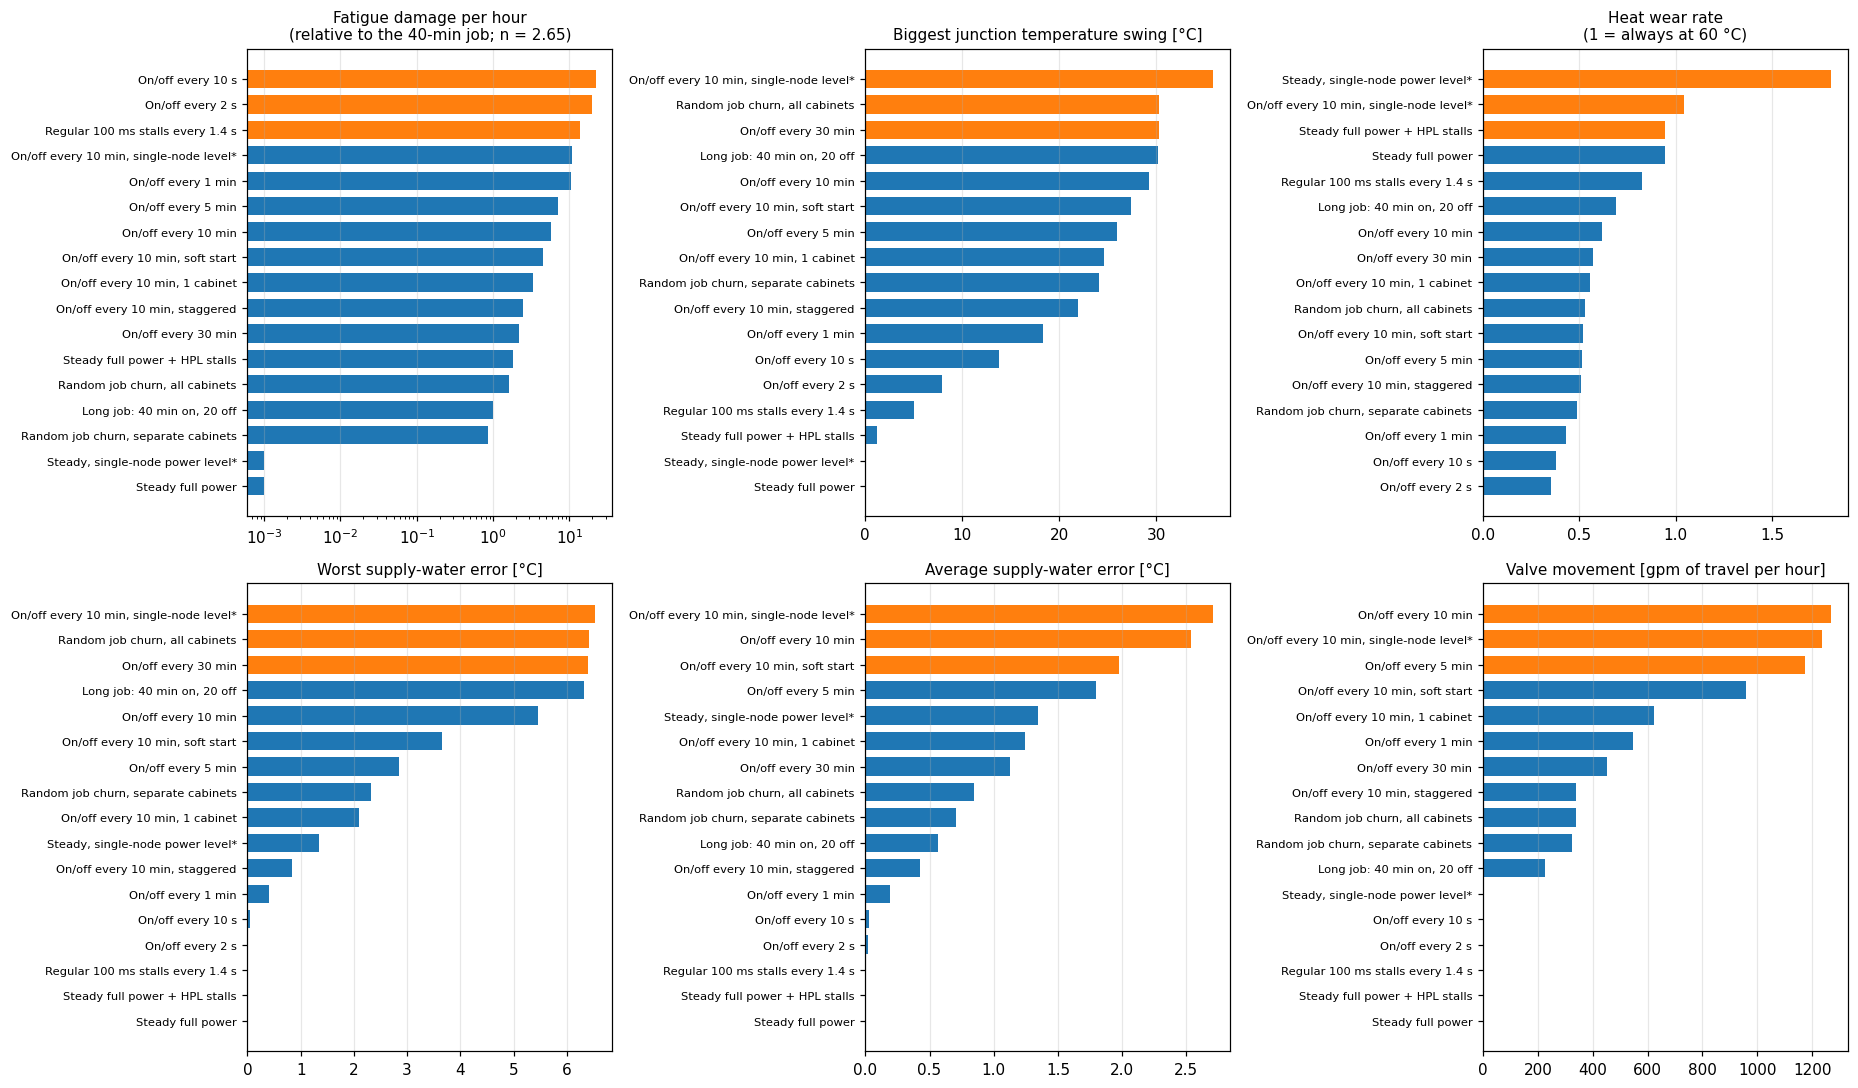

In [3]:
def fig_rankings():
    fig, ax = plt.subplots(2, 3, figsize=(17, 10))
    panels = [(ax[0, 0], 'dmg_265', 'Fatigue damage per hour\n(relative to the 40-min job; n = 2.65)', True),
              (ax[0, 1], 'Tj_swing', 'Biggest junction temperature swing [°C]', False),
              (ax[0, 2], 'wear', 'Heat wear rate\n(1 = always at 60 °C)', False),
              (ax[1, 0], 'supply_off_max', 'Worst supply-water error [°C]', False),
              (ax[1, 1], 'supply_off_mean', 'Average supply-water error [°C]', False),
              (ax[1, 2], 'valve_travel', 'Valve movement [gpm of travel per hour]', False)]
    for a, c, title, lg in panels:
        s = TAB[c].sort_values(); s_pos = s.clip(lower=1e-3) if lg else s
        a.barh(range(len(s)), s_pos, color=[CMP_C if i >= len(s) - 3 else MAIN_C for i in range(len(s))], height=0.72)
        a.set_yticks(range(len(s)), s.index, fontsize=7.5); a.set_title(title, fontsize=10); a.grid(axis='y', visible=False)
        if lg: a.set_xscale('log')
    fig.tight_layout(); fig.savefig(FIG / 'stress_rankings.png', bbox_inches='tight')

fig_rankings()

**How to read this figure.** Each panel sorts the workloads by one score, worst on top, with the three worst in orange. The top row is the chip; the bottom row is the cooling system. Notice that the order changes completely from panel to panel.

**What it shows:**

1. **Top left (fatigue, $n$ = 2.65):** rapid on/off wins, at 22× the 40-minute job for a 10 s rhythm and 20× for a 2 s rhythm. Each swing is small, but there are hundreds or thousands per hour. Note the x-axis is logarithmic. Steady full power does no fatigue damage, since nothing cycles.
2. **Top middle (biggest swing):** the slow, synchronized workloads win, at about 30 °C. They are as bad as the rapid ones are mild. The two `*` workloads go up to 36 °C.
3. **Top right (heat wear):** steady full power is the worst workload at the measured power levels (0.94), because it never gets a break. The 2 s on/off rhythm is the mildest (0.35): the chip spends half the time near idle. At the higher single-node level, wear is about twice as high (1.80).
4. **Bottom left (worst water error):** anything with a full synchronized step reaches about 6.4 °C. The 10-minute workload reaches 5.5 °C, because the water doesn't have time to settle between steps.
5. **Bottom middle (average water error):** 10 minutes is the worst at 2.5 °C. Longer cycles spend more of their time settled, and shorter cycles get averaged out by the cabinet's thermal mass.
6. **Bottom right (valve travel):** 5–10 minutes moves the valve the most, about 1 200 gpm of travel per hour.

**Three comparisons that matter most:**

* **Synchronized or not.** Random jobs on all cabinets together give a worst water error of 6.4 °C. The same kind of churn on separate cabinets gives 2.3 °C. And 10-minute cycles staggered by a third of a period give only 0.8 °C, against 5.5 °C in step. The cooling group sees the *total* of its 3 cabinets, so what one cabinet adds another can take away.
* **Size of the step.** One cabinet alone doing the 10-minute cycle gives 2.1 °C, about 40 % of the full 5.5 °C.
* **The damage threshold changes the answer.** If swings under 10 °C are harmless (`dmg_265_10K`), then the 2 s on/off and the 1.4 s stalls drop to zero, and the 10 s rhythm is the worst left. So whether "rapid small swings" matter at all depends on a threshold nobody has measured for this package.

n = 2.65: worst period for chip fatigue 0.2 s (swing 5.5 °C)
n = 4.0: worst period for chip fatigue 11.1 s (swing 14.2 °C)
n = 6.0: worst period for chip fatigue 579.6 s (swing 29.1 °C)
worst period for average supply error 9.7 min (2.52 °C); valve travel peaks at 9.7 min (1273 gpm/h)
    period_s  swing  swing_own   peak  swing_plate  supply_swing  supply_off  valve_travel
0       0.05   2.30       2.30  50.04         0.00          0.00        0.00          0.00
3       0.15   4.91       4.91  51.32         0.00          0.00        0.00          0.00
6       0.43   6.13       6.13  51.95         0.00          0.00        0.00          0.00
9       1.28   7.19       7.19  52.46         0.01          0.00        0.00          0.00
12      3.76   9.97       9.97  53.98         0.08          0.00        0.00          0.00
15     11.06  14.20      14.20  55.99         0.55          0.00        0.00          0.00
18     32.56  16.73      16.76  57.26         2.11          0.38        0.09 

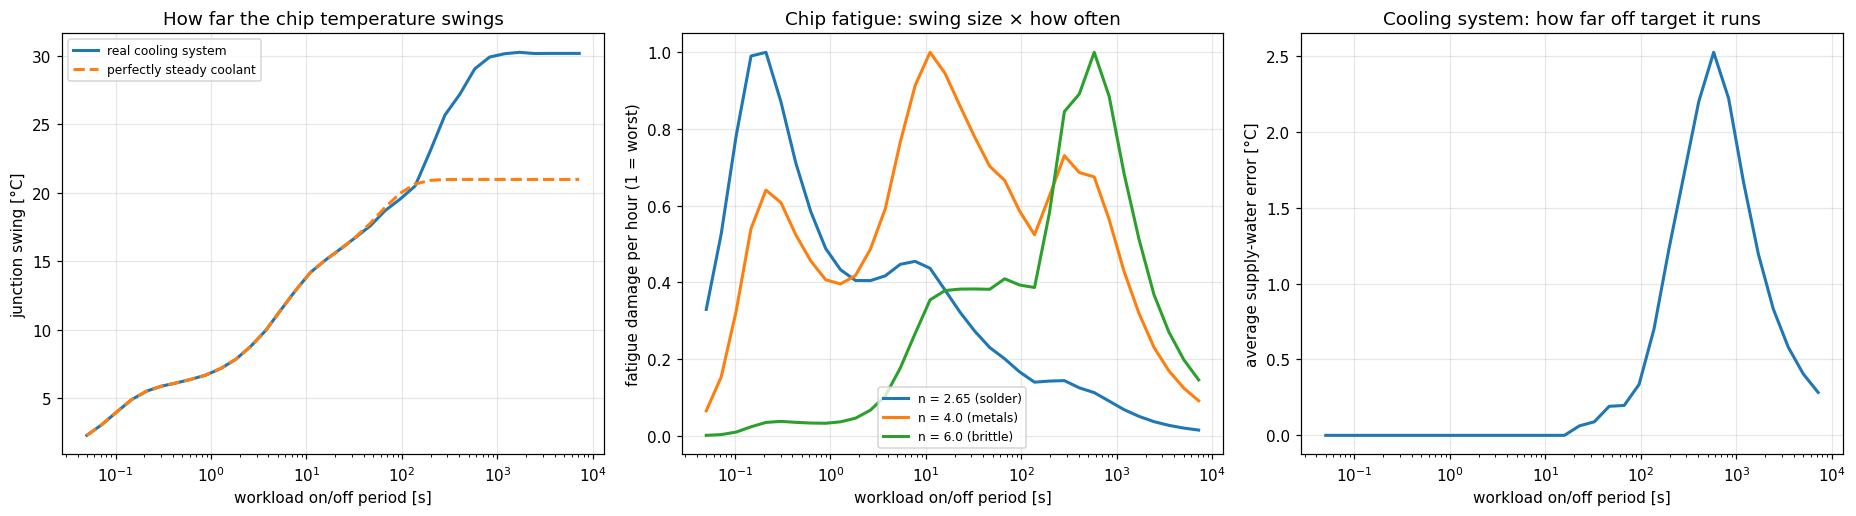

In [4]:
def period_scan(periods, n_values=(2.65, 4.0, 6.0)):
    '''For a 50 % on/off workload of each period: temperature swing and damage per hour at the hottest GPU, on the real
    cooling system and with perfectly steady coolant.'''
    jn = M['jnet'][0]; rows = []
    for P in periods:
        dt = min(P / 100, 1.0)
        if P >= 20:                                           # slow enough for the cooling group to react
            dur = int(max(6 * P, 3000)); t1 = np.arange(dur, dtype=float)
            node = square(P, t=t1)
            cg = fm.run_cooling(M, np.tile(fm.cabinet_ac_from_nodes(M, node * fm.N_NODES), (3, 1)), PIT0)
            lit = cg['LIT']; plf = cg['PLF']
        else:                                                 # the cabinet only feels the average power
            dur = int(max(10 * P, 200)); t1 = np.arange(dur, dtype=float)
            cg = fm.run_cooling(M, np.full((3, dur), float(fm.cabinet_ac_from_nodes(M, 0.5 * (NODE_HI + NODE_LO) * fm.N_NODES))), PIT0)
            lit = cg['LIT']; plf = cg['PLF']
        t = np.arange(0, dur, dt)
        pw = fm.package_from_node(M, square(P, t=t))
        full = fm.junction_response(pw, np.interp(t, t1, lit) + jn['dTc'], jn['R'], jn['C'], dt=dt)['T']
        own = fm.junction_response(pw, T_SET + jn['dTc'], jn['R'], jn['C'], dt=dt)['T']
        last = t >= dur - 2 * P; last1 = t1 >= dur - max(2 * P, 2)
        row = dict(period_s=P, swing=np.ptp(full[0][last]), swing_own=np.ptp(own[0][last]), peak=full[0][last].max(), swing_plate=np.ptp(full[2][last]),
                   supply_swing=np.ptp(lit[last1]), supply_off=np.abs(lit[last1] - T_SET).mean(), supply_off_max=np.abs(lit[last1] - T_SET).max(),
                   valve_travel=2 * np.prod(fm.rainflow(plf[last1], 1.0, min_range=1.0)[:2], axis=0).sum() * 3600 / max(2 * P, 2))
        for n in n_values:
            d = lambda sw, pk: (3600 / P) * sw ** n * (1 / P) ** (-0.136) * np.exp(-2185 / (pk + 273.15)) if sw >= 2 else 0.0
            row[f'dmg_{n}'] = d(row['swing'], row['peak'])
            row[f'dmg_own_{n}'] = d(row['swing_own'], own[0][last].max())
        rows.append(row)
    return pd.DataFrame(rows)

SCAN = period_scan(np.geomspace(0.05, 7200, 34))
SCAN.to_csv(OUT / 'workload_period_scan.csv', index=False)
for n in (2.65, 4.0, 6.0):
    i = SCAN[f'dmg_{n}'].idxmax(); print(f"n = {n}: worst period for chip fatigue {SCAN.period_s[i]:.1f} s (swing {SCAN.swing[i]:.1f} °C)")
i = SCAN.supply_off.idxmax(); print(f"worst period for average supply error {SCAN.period_s[i]/60:.1f} min ({SCAN.supply_off[i]:.2f} °C); "
                                    f"valve travel peaks at {SCAN.period_s[SCAN.valve_travel.idxmax()]/60:.1f} min ({SCAN.valve_travel.max():.0f} gpm/h)")
print(SCAN[['period_s', 'swing', 'swing_own', 'peak', 'swing_plate', 'supply_swing', 'supply_off', 'valve_travel']].round(2).iloc[::3].to_string())

def fig_scan():
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8)); P = SCAN.period_s
    a = ax[0]
    a.plot(P, SCAN.swing, color=MAIN_C, lw=2, label='real cooling system')
    a.plot(P, SCAN.swing_own, color=CMP_C, lw=2, ls='--', label='perfectly steady coolant')
    a.set(xscale='log', xlabel='workload on/off period [s]', ylabel='junction swing [°C]', title='How far the chip temperature swings'); a.legend(fontsize=8)
    a = ax[1]
    for n, c in zip((2.65, 4.0, 6.0), (MAIN_C, CMP_C, THIRD_C)):
        a.plot(P, SCAN[f'dmg_{n}'] / SCAN[f'dmg_{n}'].max(), color=c, lw=2, label=f'n = {n} ({ {2.65: "solder", 4.0: "metals", 6.0: "brittle"}[n] })')
    a.set(xscale='log', xlabel='workload on/off period [s]', ylabel='fatigue damage per hour (1 = worst)', title='Chip fatigue: swing size × how often'); a.legend(fontsize=8)
    a = ax[2]
    a.plot(P, SCAN.supply_off, color=MAIN_C, lw=2)
    a.set(xscale='log', xlabel='workload on/off period [s]', ylabel='average supply-water error [°C]', title='Cooling system: how far off target it runs')
    fig.tight_layout(); fig.savefig(FIG / 'stress_period_scan.png', bbox_inches='tight')

fig_scan()

## Part 2: Which rhythm is worst?

The catalogue only tried a few rhythms. This scan tries 34 of them, from 0.05 s to 2 hours, all as 50 % on, 50 % off. Below 20 s the cabinets can't follow the power anyway, so the coolant is held steady for those.

**How to read this figure.** The x-axis is how long one on/off cycle takes, on a logarithmic scale: 1 s, 10 s, 100 s (under 2 minutes), 1000 s (about 17 minutes).

* **Left: how far the chip swings.** The dashed line is what the swing would be with perfect, unchanging coolant. Up to ~2 minutes the two lines agree, because the coolant barely moves. Above that, the solid line climbs to about 30 °C while the dashed one stays at 21 °C. **That gap of about 9 °C is what the cooling system's lag adds.**
* **Middle: fatigue damage.** Swing size matters and so does how often it happens, so the damage per hour has peaks. Each curve is scaled so its own worst point is 1. **The three curves peak in three different places:** about 0.2 s for solder-like $n$ = 2.65, 11 s for $n$ = 4, and about 10 min for brittle $n$ = 6.
* **Right: the cooling system** is simple: one peak, at about 10 minutes.

**Conclusions.**

* The cooling system's worst rhythm (~10 min) has been found clearly, since it doesn't depend on any material assumption.
* The chip's worst rhythm depends on the failure mode. The 0.2 s peak is the shakiest. It comes from swings of only about 5 °C, far faster than the slow thermal-cycling tests these constants come from, and swings that size may be too small to damage anything.
* The brittle-layer peak coincides with the cooling peak. That workload is where the two problems stack.

**A real example of a fast rhythm:** HPL itself. In the single-node trace, the GPU drops by several °C at each panel stall, about every 1.4 s, for the whole run.

                                   die_um  plate_um  paste_slip_um  paste_slip_own_um  bump_um  bump_strain_pct
workload                                                                                                       
Steady full power + HPL stalls       0.16      0.00           0.16               0.16     0.75             1.06
Regular 100 ms stalls every 1.4 s    0.29      0.00           0.29               0.29     1.40             2.01
On/off every 10 s                    0.68      0.14           0.62               0.62     3.26             4.66
On/off every 1 min                   0.91      1.15           1.36               1.40     4.33             6.18
On/off every 10 min                  1.45      4.58           3.50               1.90     6.90             9.86
Long job: 40 min on, 20 off          1.49      4.88           3.38               1.90     7.12            10.17
On/off every 10 min, soft start      1.36      3.98           2.65               0.91     6.47          

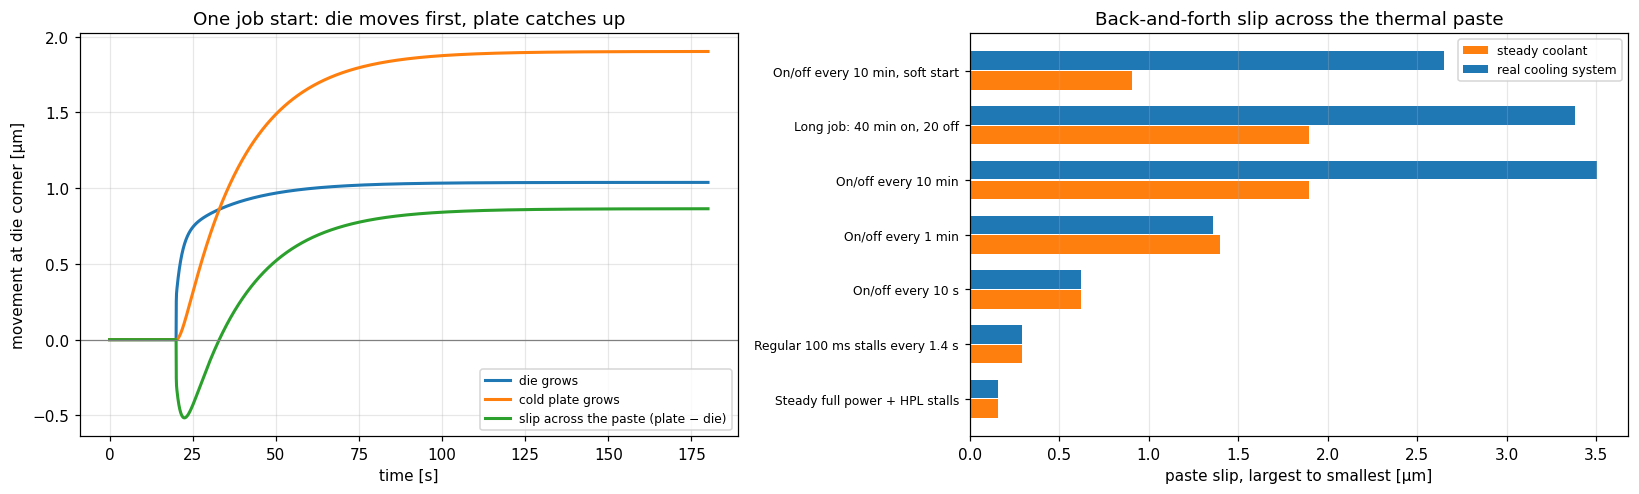

In [5]:
# Shape and size of one die [assumed from public numbers; see the table above]
DIE_SIDE_MM = np.sqrt(724.0); DNP_MM = DIE_SIDE_MM / np.sqrt(2)      # centre to corner of one 724 mm^2 GCD
ALPHA_SI, ALPHA_CU, ALPHA_SUB = 2.6e-6, 17e-6, 15e-6                 # how much each material grows per °C, per unit length
BUMP_H_UM = 70.0                                                     # solder bump height: typical value, not an MI250X measurement

def movement(T, i0=0):
    '''Growth at the die corner [µm] since sample i0: die, cold plate, slip across the thermal paste, and the bump mismatch range.'''
    d1, d2, d3 = T[0] - T[0][i0], T[1] - T[1][i0], T[2] - T[2][i0]
    um = DNP_MM * 1e3
    die, plate = ALPHA_SI * d1 * um, ALPHA_CU * d3 * um
    return dict(die=die, plate=plate, tim_slip=plate - die, bump_hi=(ALPHA_SUB * d1 - ALPHA_SI * d1) * um, bump_lo=(ALPHA_SUB * d2 - ALPHA_SI * d1) * um)

rows = []
for k in ['Steady full power + HPL stalls', 'Regular 100 ms stalls every 1.4 s', 'On/off every 10 s', 'On/off every 1 min', 'On/off every 10 min', 'Long job: 40 min on, 20 off', 'On/off every 10 min, soft start']:
    r = RUNS[k]; keep = r['t'] >= DROP_S
    mv = movement(r['T'][:, keep]); own = fm.junction_response(r['P'], T_SET + M['jnet'][0]['dTc'], M['jnet'][0]['R'], M['jnet'][0]['C'], dt=DT_W)['T'][:, keep]
    mo = movement(own)
    rows.append(dict(workload=k, die_um=np.ptp(mv['die']), plate_um=np.ptp(mv['plate']), paste_slip_um=np.ptp(mv['tim_slip']), paste_slip_own_um=np.ptp(mo['tim_slip']),
                     bump_um=np.ptp(mv['bump_hi']), bump_strain_pct=np.ptp(mv['bump_hi']) / BUMP_H_UM * 100))
MOVE = pd.DataFrame(rows).set_index('workload'); MOVE.to_csv(OUT / 'workload_expansion.csv'); print(MOVE.round(2).to_string())

# A single job start, close up: 1 minute of a step from idle to full power on steady coolant
jn = M['jnet'][0]; ts = np.arange(0, 180, DT_W)
ps = np.where(ts < 20, fm.package_from_node(M, NODE_LO), fm.package_from_node(M, NODE_HI))
step = fm.junction_response(ps, T_SET + jn['dTc'], jn['R'], jn['C'], dt=DT_W)['T']; mvs = movement(step)
# Per degree: what 1 °C does to the paste layer, when it comes from the coolant versus from the chip's own power
dT_own = np.array([jn['R'].sum(), jn['R'][1:].sum(), jn['R'][2:].sum()]) / jn['R'].sum()     # settled rise of die, middle, plate per 1 °C of junction rise
slip_own = (ALPHA_CU * dT_own[2] - ALPHA_SI * dT_own[0]) * DNP_MM * 1e3
slip_cool = (ALPHA_CU - ALPHA_SI) * DNP_MM * 1e3
print(f"\npaste slip per 1 °C of junction rise: {slip_own:.3f} µm from the chip's own power, {slip_cool:.3f} µm from warmer coolant ({slip_cool / slip_own:.1f} times as much)")
print(f"step job start: paste slip goes to {mvs['tim_slip'].min():.2f} µm early on and settles at {mvs['tim_slip'][-1]:.2f} µm")

def fig_move():
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
    a = ax[0]; a.plot(ts, mvs['die'], color=MAIN_C, lw=2, label='die grows'); a.plot(ts, mvs['plate'], color=CMP_C, lw=2, label='cold plate grows')
    a.plot(ts, mvs['tim_slip'], color=THIRD_C, lw=2, label='slip across the paste (plate − die)'); a.axhline(0, color='0.5', lw=0.8)
    a.set(xlabel='time [s]', ylabel='movement at die corner [µm]', title='One job start: die moves first, plate catches up'); a.legend(fontsize=8)
    a = ax[1]; y = np.arange(len(MOVE))
    a.barh(y - 0.18, MOVE.paste_slip_own_um, height=0.34, color=CMP_C, label='steady coolant')
    a.barh(y + 0.18, MOVE.paste_slip_um, height=0.34, color=MAIN_C, label='real cooling system')
    a.set_yticks(y, MOVE.index, fontsize=8); a.set(xlabel='paste slip, largest to smallest [µm]', title='Back-and-forth slip across the thermal paste'); a.grid(axis='y', visible=False); a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / 'stress_expansion.png', bbox_inches='tight')

fig_move()

## Part 3: Expansion and contraction

**The idea.** Materials grow when heated, and different materials grow by different amounts. A GPU is a sandwich: a silicon die, thermal paste on top with a copper cold plate above it, and solder bumps below connecting it to the package substrate. Each time the temperature changes, these layers try to grow by different amounts and pull on whatever joins them. Do that thousands of times and joints crack, and paste gets squeezed out ("pump-out") [3, 4].

| Material | Growth per °C | Over 19 mm and 30 °C |
|---|---|---|
| Silicon | 2.6 millionths | 1.5 µm |
| Copper | 17 millionths | 9.7 µm |
| Organic substrate | ~15 millionths (published range 10–20 [3]) | 8.6 µm |

For scale: a human hair is about 70 µm thick. The 19 mm is the distance from the centre to the corner of one 724 mm² die, where movement is largest.

**How to read the left figure: one job starting.** Power jumps at t = 20 s.

1. The **die** (blue) reacts first, within a fraction of a second, because it is where the heat is made.
2. The **cold plate** (orange) follows over about 30 s. It warms by less, but copper grows far more per degree, so it ends up moving further.
3. **The slip across the paste** (green) is the difference between them. It first goes **negative (−0.5 µm)** as the die leads, then reverses to **positive (+0.9 µm)** as the plate overtakes. So **every sudden job start works the paste in both directions**, a total of about 1.4 µm.

**How to read the right figure: slip per workload.** Orange is steady coolant, blue is the real cooling system. Above about a minute, the blue bars pull away.

* **On 10-minute cycles the coolant nearly doubles the paste slip:** 1.9 → 3.5 µm.
* **Why:** warmer coolant heats the whole stack evenly, so copper's large growth acts in full. Per degree of chip temperature, the coolant drags the paste **6.7 times** more than the chip's own power does (0.27 vs. 0.04 µm/°C).
* **Soft starts help the paste a lot:** with steady coolant the slip falls from 1.9 to 0.9 µm, because the die no longer leads the plate at each step. On the real cooling system it falls from 3.5 to 2.7 µm.
* **Rapid rhythms hardly move the paste**, since the plate never reacts. They do still flex the die and the bumps below it.

**The solder bumps.** In the table above, `bump_um` is the mismatch across the bumps, about 7 µm on the slow workloads. Over a 70 µm bump that would be about 10 % strain. **That's an upper limit, and a crude one.** It assumes the substrate is as hot as the die, and ignores the underfill glue that shares this load in real packages. Don't use it as a real strain. The comparison between workloads is the useful part: bump mismatch follows the junction swing, so it is largest on the workloads with the biggest swings.

**Assumptions in this section:** the ladder's three layers are read as die, package and cold plate, the die temperature comes from a hotspot sensor (so it overstates the die's average), and copper and bump dimensions are typical values, not MI250X measurements. Real large dies also bow rather than just stretch, and published work ties that bowing to pump-out [3, 4]. A flat-layer estimate like this can't capture it.


On/off every 10 min
                                         Tj_max  Tj_swing  supply_off_max  supply_off_mean  dmg_265_rel  dmg_6_rel  wear_rel  valve_travel_rel
option                                                                                                                                        
Today (baseline)                          64.53     29.25            5.46             2.53         1.00       1.00      1.00              1.00
Thermometer 58 s faster                   61.85     25.75            2.54             1.77         0.68       0.44      0.93              0.74
Valve also watches power (feed-forward)   59.29     21.39            1.16             0.38         0.39       0.14      0.82              0.92
Mixing tank in the loop (60 s)            63.22     27.87            3.91             2.28         0.85       0.73      0.89              0.84
Heat exchanger 50 % larger                64.67     29.28            5.61             2.46         1.00       1.00      1

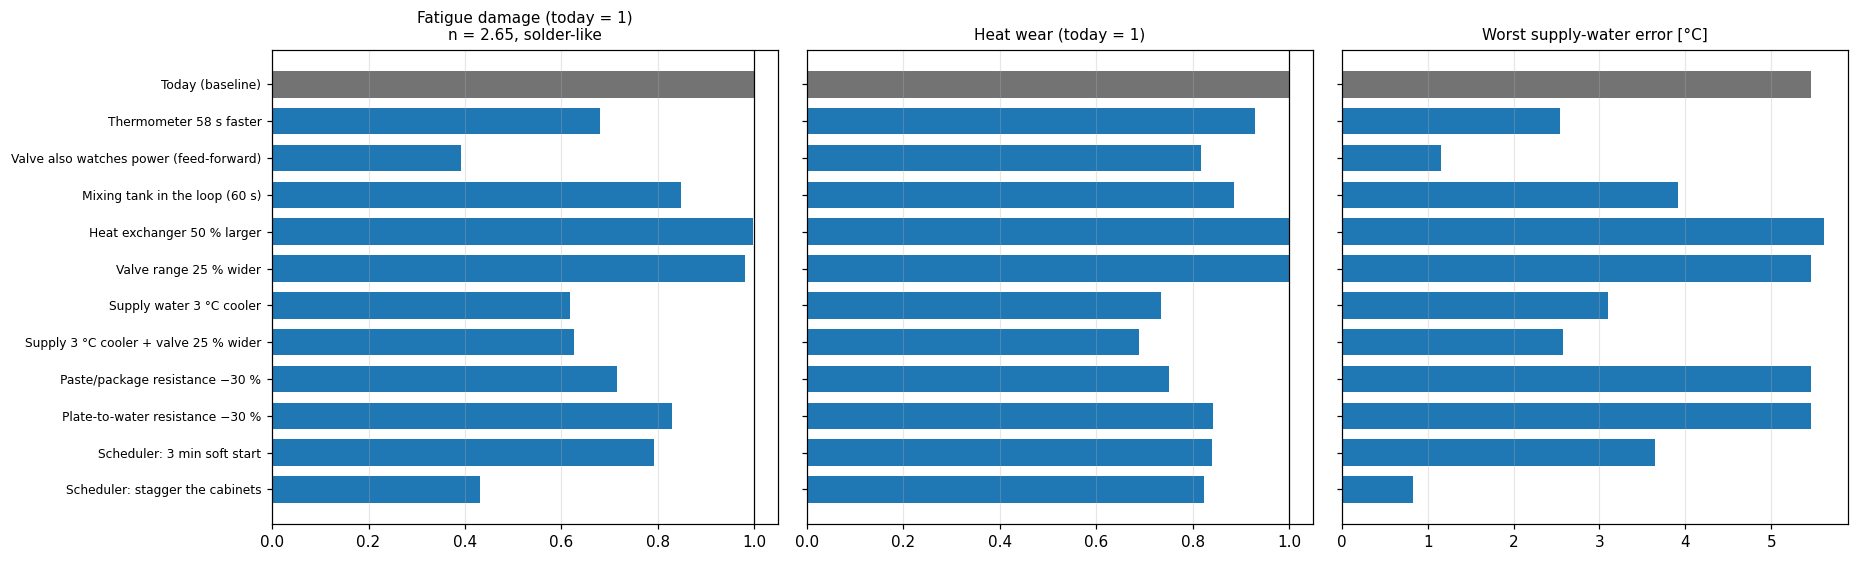

In [6]:
# Each option is tried on two hard workloads. Only one thing changes at a time.
SLOPE = (fm.run_cooling(M, np.full((3, 3000), float(fm.cabinet_ac_from_nodes(M, NODE_HI * fm.N_NODES))), PIT0)['PLF'][-1]
         - fm.run_cooling(M, np.full((3, 3000), float(fm.cabinet_ac_from_nodes(M, NODE_LO * fm.N_NODES))), PIT0)['PLF'][-1]) / \
        (3 * (float(fm.cabinet_ac_from_nodes(M, NODE_HI * fm.N_NODES)) - float(fm.cabinet_ac_from_nodes(M, NODE_LO * fm.N_NODES))))
RATE = 0.94                                       # the fastest the valve was seen moving in the data, gpm/s (30 s average)
hi_flow = M['ctl']['plf_range'][1]; lo_flow = M['ctl']['plf_range'][0]

def with_R(model, f2=1.0, f3=1.0):
    '''A copy of the model with the paste/package layer and/or the plate-to-water layer resistance scaled.'''
    out = fm.with_changes(model)
    for j in out['jnet']:
        j['R'] = j['R'] * np.array([1, f2, f3])
    return out

OPTIONS = {
    'Today (baseline)':                 (M, None),
    'Thermometer 58 s faster':          (fm.with_changes(M, ctl=dict(d_c=10.0)), None),
    'Valve also watches power (feed-forward)': (fm.with_changes(M, ctl=dict(Kff=SLOPE, ff_tau=70.0, rate=RATE)), None),
    'Mixing tank in the loop (60 s)':   (fm.with_changes(M, cdu=dict(tau_s=60.0)), None),
    'Heat exchanger 50 % larger':       (fm.with_changes(M, cdu=dict(UA_hx=1.5 * M['cdu']['UA_hx'])), None),
    'Valve range 25 % wider':           (fm.with_changes(M, ctl=dict(plf_range=(lo_flow, 1.25 * hi_flow))), None),
    'Supply water 3 °C cooler':         (fm.with_changes(M, ctl=dict(T_set=T_SET - 3)), None),
    'Supply 3 °C cooler + valve 25 % wider': (fm.with_changes(M, ctl=dict(T_set=T_SET - 3, plf_range=(lo_flow, 1.25 * hi_flow))), None),
    'Paste/package resistance −30 %':   (with_R(M, f2=0.7), None),
    'Plate-to-water resistance −30 %':  (with_R(M, f3=0.7), None),
    'Scheduler: 3 min soft start':      (M, 'soft'),
    'Scheduler: stagger the cabinets':  (M, 'stagger'),
}
def option_workload(base, change):
    node, st = WORKLOADS[base]
    if change == 'soft':
        return soft(node, 180), st
    if change == 'stagger':
        return np.array([np.roll(node[0], int(j * 200 / DT_W)) for j in range(3)]), st
    return node, st

rows = []
for base in ['On/off every 10 min', 'Long job: 40 min on, 20 off']:
    for name, (mod, change) in OPTIONS.items():
        s = score(run_workload(*option_workload(base, change), model=mod), model=mod)
        rows.append(dict(workload=base, option=name, **s))
WHATIF = pd.DataFrame(rows)
for c in ('dmg_265', 'dmg_6', 'wear', 'valve_travel'):
    WHATIF[c + '_rel'] = WHATIF[c] / WHATIF.groupby('workload')[c].transform('first')
WHATIF.to_csv(OUT / 'cooling_decisions_whatif.csv', index=False)
show = ['Tj_max', 'Tj_swing', 'supply_off_max', 'supply_off_mean', 'dmg_265_rel', 'dmg_6_rel', 'wear_rel', 'valve_travel_rel']
for b, grp in WHATIF.groupby('workload', sort=False):
    print('\n' + b); print(grp.set_index('option')[show].round(2).to_string())

def fig_whatif():
    W = WHATIF[WHATIF.workload == 'On/off every 10 min'].set_index('option')
    fig, ax = plt.subplots(1, 3, figsize=(17, 5.2)); y = np.arange(len(W))
    for a, c, t in [(ax[0], 'dmg_265_rel', 'Fatigue damage (today = 1)\nn = 2.65, solder-like'), (ax[1], 'wear_rel', 'Heat wear (today = 1)'), (ax[2], 'supply_off_max', 'Worst supply-water error [°C]')]:
        a.barh(y, W[c], color=[POWER_C] + [MAIN_C] * (len(W) - 1), height=0.72); a.invert_yaxis(); a.set_title(t, fontsize=10); a.grid(axis='y', visible=False)
        a.set_yticks(y, W.index if a is ax[0] else [''] * len(W), fontsize=8)
        if c != 'supply_off_max': a.axvline(1, color='k', lw=0.8)
    fig.tight_layout(); fig.savefig(FIG / 'stress_decisions.png', bbox_inches='tight')

fig_whatif()

In [7]:
# Is feed-forward fragile? Try it with deliberately wrong settings, on the 10-minute workload and on the real HPL run.
t_ff = np.arange(7200.0); ac_ff = np.tile(np.where(t_ff % 600 < 300, *[float(fm.cabinet_ac_from_nodes(M, x * fm.N_NODES)) for x in (NODE_HI, NODE_LO)]), (3, 1))
def ff_row(label, **c):
    r = fm.run_cooling(fm.with_changes(M, ctl=c), ac_ff, PIT0); k = t_ff >= 3600
    print(f"{label:28s} worst error {np.abs(r['LIT'][k] - T_SET).max():.2f} °C, average {np.abs(r['LIT'][k] - T_SET).mean():.2f} °C")
ff_row('Today, no feed-forward')
BASE_FF = dict(Kff=SLOPE, ff_tau=70.0, rate=RATE); ff_row('Feed-forward as chosen', **BASE_FF)
for f in (0.5, 1.5): ff_row(f'Gain x {f}', **{**BASE_FF, 'Kff': SLOPE * f})
for tau in (30.0, 120.0): ff_row(f'Heat lag guess {tau:.0f} s', **{**BASE_FF, 'ff_tau': tau})
for v in (0.25, 0.5): ff_row(f'Valve limited to {v} gpm/s', **{**BASE_FF, 'rate': v})
for label, c in [('today', {}), ('feed-forward', BASE_FF)]:
    r = fm.run_cooling(fm.with_changes(M, ctl=c), AC_M, PIT_M)
    print(f"real HPL run, {label}: supply peaks at {r['LIT'].max():.1f} °C, lowest {r['LIT'][300:].min():.1f} °C")

Today, no feed-forward       worst error 5.46 °C, average 2.53 °C
Feed-forward as chosen       worst error 1.16 °C, average 0.38 °C
Gain x 0.5                   worst error 2.48 °C, average 1.31 °C


Gain x 1.5                   worst error 2.17 °C, average 0.75 °C
Heat lag guess 30 s          worst error 2.36 °C, average 0.87 °C
Heat lag guess 120 s         worst error 1.76 °C, average 0.56 °C


Valve limited to 0.25 gpm/s  worst error 3.68 °C, average 2.00 °C
Valve limited to 0.5 gpm/s   worst error 2.64 °C, average 0.81 °C
real HPL run, today: supply peaks at 33.3 °C, lowest 26.1 °C


real HPL run, feed-forward: supply peaks at 29.0 °C, lowest 28.0 °C


## Part 4: Using the model to decide what to change

**The method.** Change one thing in the model, rerun the same workload, and compare. That's what this cell does, on two hard workloads. It's far cheaper than changing real hardware, and it shows which options are worth a real trial.

**How to read the figure.** Each bar is one option on the 10-minute workload. Grey is today. For the two left panels, today = 1, so a bar reaching 0.5 means half the damage. Shorter is better in all three panels.

**What each option does in real life, and what the model says** (10-minute workload):

| Option | What it means | Fatigue, $n$ = 2.65 | Fatigue, $n$ = 6 | Heat wear | Worst water error (today 5.5 °C) |
|---|---|---|---|---|---|
| **Valve also watches power** | Open the valve as heat is about to arrive, instead of waiting to feel the water warm. A control change | **0.39** | **0.14** | 0.82 | **1.2 °C** |
| **Stagger the cabinets** | Scheduler avoids stepping all 3 cabinets together. A policy change | **0.43** | **0.17** | 0.82 | **0.8 °C** |
| Supply water 3 °C cooler | Lower the setpoint | 0.62 | 0.39 | **0.73** | 3.1 °C |
| Thermometer 58 s faster | Shorten the ~1 minute delay before the valve reacts | 0.68 | 0.44 | 0.93 | 2.5 °C |
| Better paste/package (−30 %) | A hardware change at the chip | 0.71 | 0.51 | **0.75** | 5.5 °C |
| 3 min soft start | Scheduler ramps power up and down | 0.79 | 0.63 | 0.84 | 3.7 °C |
| Better cold plate (−30 %) | A hardware change at the plate | 0.83 | 0.69 | 0.84 | 5.5 °C |
| Mixing tank (60 s) | Extra water volume in the loop | 0.85 | 0.73 | 0.89 | 3.9 °C |
| Valve range 25 % wider | More flow available | 0.98 | 0.98 | 1.00 | 5.5 °C |
| Heat exchanger 50 % larger | More exchanger area | 1.00 | 1.00 | 1.00 | 5.6 °C |

**What to conclude.**

1. **Fix the timing before buying hardware.** The problem in these workloads is that the valve reacts late, not that the system lacks capacity. That's why a larger heat exchanger and a wider valve range do nothing here, while control changes do the most.
2. **Feed-forward looks like the best first trial.** It uses cabinet power data that is already measured. It also held up when I changed its settings: with the gain off by ±50 %, a 30–120 s lag, or a valve as slow as 0.25 gpm/s, it still beat today's behaviour (see the printed test just above this text). On the real HPL run, the model's peak supply falls from 33.3 to 29.0 °C. A warning: the model assumes the ~1 minute delay is in *sensing*, and that the valve can move at the 0.94 gpm/s it was seen moving. If the real delay is in the valve itself, the gain will be smaller.
3. **Different goals want different fixes.** Against heat wear, a cooler supply and better paste do the most. Against fatigue and paste slip, reducing the swing does the most. Better paste also helps during steady running; control changes only help when power changes.
4. **On long steady jobs, control changes do little for heat wear** (wear 0.97–1.0 on the 40-minute job), because the steady part dominates. There, only better paste or plates (0.74–0.83) or a cooler supply with enough flow (0.76) help.
5. **A cooler supply needs more flow to hold at peak load.** With today's valve range, a 3 °C lower setpoint can't be held at full power. On the 40-minute job the supply runs 2.2 °C off target on average, against 0.7 °C with a 25 % wider range. This is the one case where a wider valve helps.

**What's not in the model: cost.** Frontier's warm water is what makes its cooling cheap. A colder setpoint means more chiller use in warm weather, and the model can't price that. Better paste means changing hardware across 37 888 GPUs. Weigh the benefits above against those costs.

**How to use this for future decisions:**

1. Put the candidate workload, or a mix of real job logs, through `run_workload`.
2. Change the model with `fm.with_changes(...)` to represent the option, and rerun.
3. Report the ratio to today for each damage type, under several $n$ values. Only trust conclusions that hold for all of them.
4. Try the best option on one real cooling group, and refit the model to the results.
5. To turn ratios into real lifetimes, compare them against failure records. Ostrouchov et al. did this for Titan's GPUs and found reliability tied to heat dissipation, cooling layout and job scheduling [5]. Doing the same on Frontier would calibrate this model against real failures.

In [8]:
# How much margin does the valve have as the facility water warms up? (Hold the setpoint fixed.)
rows = []
for pit in (18, 20, 21.2, 22, 24, 26):
    for label, nw in [('idle', NODE_LO), ('peak measured', NODE_HI), ('single-node level', NODE_SOLO)]:
        ac = float(fm.cabinet_ac_from_nodes(M, nw * fm.N_NODES))
        s = fm.run_cooling(M, np.full((3, 3000), ac), pit)
        rows.append(dict(facility_C=pit, load=label, group_kW=3 * ac / 1e3, supply_C=s['LIT'][-1], flow_gpm=s['PLF'][-1]))
MARGIN = pd.DataFrame(rows)
print(MARGIN.pivot(index='facility_C', columns='load', values='supply_C').round(1)[['idle', 'peak measured', 'single-node level']].to_string())

load        idle  peak measured  single-node level
facility_C                                        
18.0        25.6           28.6               28.6
20.0        27.6           28.6               28.8
21.2        28.6           28.6               30.0
22.0        28.6           29.4               30.8
24.0        28.6           31.4               32.8
26.0        28.6           33.4               34.8


**Reading the table.** Each number is the settled supply water temperature, with the setpoint fixed at 28.6 °C. Going across the table increases the load; going down warms the facility water.

* **At today's 21.2 °C, the measured peak just holds** (the valve is at 208 of 209 gpm). This cooling group has almost no flow margin at peak load.
* **Above about 21–22 °C of facility water, the setpoint is lost at peak load:** the supply rises roughly 1 °C per 1 °C. Sun et al.'s and Jadhav & Liu's plant data show the facility water running from about 12 °C in winter to about 29 °C in summer [6, 7], so this matters.
* **At 18–20 °C and idle, the supply drops below setpoint** because the valve reaches its low end.

**Be careful with this one.** The valve limits are just the highest and lowest flows seen in one 47-minute run. Those could be real limits, or simply what that run needed. Frontier also likely changes its setpoint with the seasons. So read this table as "here's where to look", and check the real valve limits before relying on it. Summer data would settle the question.

estimated flow past each GPU: 3.2 L/min (223 W/K)
fitted total resistance per GPU: [0.0553 0.0441 0.0541 0.0417] K/W; spread 0.0136 K/W
if 3 upstream GPUs warm the same stream, the last GPU gains 0.0135 K per W of each GPU's power (a check, not a fit)
variable-flow solver vs fixed-flow solver at the reference flow: largest difference 0.0104 °C
    0.5 L/min: junction above inlet at 560 W =  30.2 °C (n=0.0),  32.5 °C (n=0.33),  39.7 °C (n=0.8)
    1.0 L/min: junction above inlet at 560 W =  26.1 °C (n=0.0),  27.4 °C (n=0.33),  30.4 °C (n=0.8)
    2.0 L/min: junction above inlet at 560 W =  24.1 °C (n=0.0),  24.6 °C (n=0.33),  25.4 °C (n=0.8)
    3.2 L/min: junction above inlet at 560 W =  23.4 °C (n=0.0),  23.4 °C (n=0.33),  23.4 °C (n=0.8)
    6.0 L/min: junction above inlet at 560 W =  22.8 °C (n=0.0),  22.2 °C (n=0.33),  21.7 °C (n=0.8)
   10.0 L/min: junction above inlet at 560 W =  22.5 °C (n=0.0),  21.6 °C (n=0.33),  20.8 °C (n=0.8)


60 s on/off, 560/90 W: swing 18.5 °C at fixed flow, 16.8 °C with flow cut to 0.5 L/min while idle (9 % smaller)


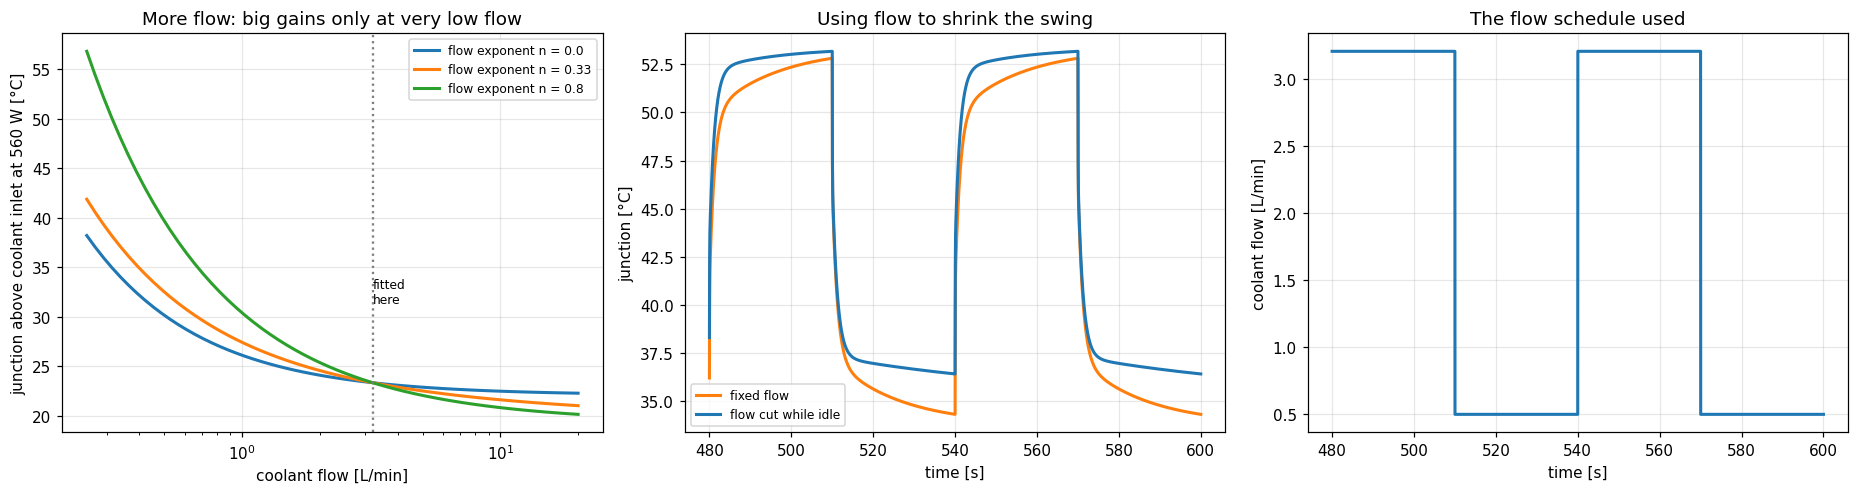

In [9]:
# Flow through one GPU's cold plate at the conditions the ladder was fitted at (an estimate)
mcp_cab = np.mean([c['mcp'] for c in M['cab']])
FLOW_REF_LPM = mcp_cab / fm.N_NODES / fm.GPM_WK * fm.GPM_TO_LPM       # one node's stream; assumes all 4 GPUs share it in series
print(f"estimated flow past each GPU: {FLOW_REF_LPM:.1f} L/min ({mcp_cab / fm.N_NODES:.0f} W/K)")
Rt = [j['R'].sum() for j in M['jnet']]
print(f"fitted total resistance per GPU: {np.round(Rt, 4)} K/W; spread {max(Rt) - min(Rt):.4f} K/W")
print(f"if 3 upstream GPUs warm the same stream, the last GPU gains {3 / (mcp_cab / fm.N_NODES):.4f} K per W of each GPU's power (a check, not a fit)")

JN1 = M['jnet'][3]                                                    # lowest resistance, so the least upstream heating mixed into it
# Check: at the reference flow the variable-flow solver must agree with the fixed-flow one
tt = np.arange(0, 120, 0.01); pp = np.where(tt < 20, 90.0, 560.0)
a_ = fm.single_gpu(pp, FLOW_REF_LPM, 30.0, JN1, FLOW_REF_LPM)['T'][0]; b_ = fm.junction_response(pp, 30.0, JN1['R'], JN1['C'], dt=0.01)['T'][0]
print(f"variable-flow solver vs fixed-flow solver at the reference flow: largest difference {np.abs(a_ - b_).max():.4f} °C")

flows = np.geomspace(0.25, 20, 60); FIXED = {}
for n in (0.0, 0.33, 0.8):
    FIXED[n] = np.array([fm.single_gpu_flow_ladder(JN1['R'], f, FLOW_REF_LPM, n)[0].sum() for f in flows])
for f in (0.5, 1, 2, FLOW_REF_LPM, 6, 10):
    print(f"  {f:5.1f} L/min: junction above inlet at 560 W = " + ', '.join(f"{560 * np.interp(f, flows, FIXED[n]):5.1f} °C (n={n})" for n in FIXED))

# Can changing flow cancel a power swing? A 60 s on/off workload, with flow fixed vs flow that drops while the GPU idles
ta = np.arange(0, 600, 0.01); pa = np.where((ta % 60) < 30, 560.0, 90.0)
fixed = fm.single_gpu(pa, FLOW_REF_LPM, 30.0, JN1, FLOW_REF_LPM)
flow_v = np.where((ta % 60) < 30, FLOW_REF_LPM, 0.5)
vary = fm.single_gpu(pa, flow_v, 30.0, JN1, FLOW_REF_LPM)
last = ta > 480
sw_f, sw_v = np.ptp(fixed['T'][0][last]), np.ptp(vary['T'][0][last])
print(f"60 s on/off, 560/90 W: swing {sw_f:.1f} °C at fixed flow, {sw_v:.1f} °C with flow cut to 0.5 L/min while idle ({(1 - sw_v / sw_f) * 100:.0f} % smaller)")

def fig_single():
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    a = ax[0]
    for n, c in zip(FIXED, (MAIN_C, CMP_C, THIRD_C)):
        a.plot(flows, 560 * FIXED[n], color=c, lw=2, label=f'flow exponent n = {n}')
    a.axvline(FLOW_REF_LPM, color='0.5', ls=':'); a.annotate('fitted\nhere', (FLOW_REF_LPM, 560 * FIXED[0.33].max() * 0.75), fontsize=8)
    a.set(xscale='log', xlabel='coolant flow [L/min]', ylabel='junction above coolant inlet at 560 W [°C]', title='More flow: big gains only at very low flow'); a.legend(fontsize=8)
    m = ta > 480
    a = ax[1]; a.plot(ta[m], fixed['T'][0][m], color=CMP_C, lw=2, label='fixed flow'); a.plot(ta[m], vary['T'][0][m], color=MAIN_C, lw=2, label='flow cut while idle')
    a.set(xlabel='time [s]', ylabel='junction [°C]', title='Using flow to shrink the swing'); a.legend(fontsize=8)
    a = ax[2]; a.plot(ta[m], flow_v[m], color=MAIN_C, lw=2); a.set(xlabel='time [s]', ylabel='coolant flow [L/min]', title='The flow schedule used')
    fig.tight_layout(); fig.savefig(FIG / 'stress_single_gpu.png', bbox_inches='tight')

fig_single()

## Part 5: One GPU on a cold plate with variable coolant flow

**Short answer: yes, with one assumed piece.** `fm.single_gpu(power, flow, inlet_temp, ...)` does this, and flow can change over time.

**How it works.** The fitted ladder has three resistances in a row: die → package → cold plate → water. Flow only affects the last one. That one is split into two parts:

* **Water warming up along the plate.** Less flow means the water heats more. This follows from energy conservation and goes as 1/flow, so it isn't an assumption.
* **Heat getting from metal into water.** This goes as $1/\text{flow}^n$, and $n$ **is an assumption**. Nothing in our data varied the flow past a GPU. Laminar cold plates have $n$ near 0 once the flow is fully developed, with some increase from entrance effects [8]. I use $n$ = 0.33, and show 0 and 0.8 to bracket it.

**Reference flow.** The fit happened at one flow, estimated at 3.2 L/min per GPU: one node's share of the cabinet's flow, assuming the node's 4 GPUs share one stream in series.

A useful check: the printed numbers show the GPUs' fitted resistances differ by 0.0136 K/W. If 3 upstream GPUs warm the same stream, the last GPU should gain 0.0135 K per W of GPU power. That's a striking match, and it supports the series picture, though one number can't prove it. Package 3 has the lowest resistance, so it has the least upstream heating mixed in, and it is what's used here.

**How to read the figure.**

* **Left:** junction temperature above the coolant inlet at 560 W, against flow. The three lines are the three values of $n$, and they all cross at the fitted flow. **The curve is nearly flat above about 2 L/min**, and steep below 1 L/min. At 3.2 L/min it is 23.4 °C. Tripling the flow to 10 L/min gains only 1–3 °C. Cutting it to 0.5 L/min costs 7–16 °C.
* **Middle and right:** could changing the flow cancel a power swing, by slowing it while the GPU idles so the chip stays warmer? It only shrinks an 18.5 °C swing to 16.8 °C (9 %), even with a big cut in flow.

**Why flow matters so little:** only about a sixth of the total resistance is in the flow-dependent layer. The other five-sixths are the die and package, which water can't reach. Better paste beats more flow.

**Limits.**

* **Your cold plate may differ.** On a different plate or bench, the last resistance and heat capacity would change. To calibrate: run a power step at 3 flows, and fit them.
* **Inlet is yours to set.** On a bench with a single GPU, there are no upstream GPUs, so `T_in_C` is simply your inlet temperature.
* **Single-phase water only.** No boiling, and low-flow results rely on the assumed scaling. At very low flow the real plate may behave differently.

```python
out = fm.single_gpu(P_W=my_power, flow_lpm=my_flow, T_in_C=30.0, jn=M['jnet'][3], flow_ref_lpm=FLOW_REF_LPM, dt=0.01)
junction = out['T'][0]
```

## Part 6: The simple function

Give it cabinet power, and it gives you the cooling system's response. It's one self-contained function with the fitted numbers inside, so you can copy it into any script (it needs only numpy and pandas).

```python
result = predict_cooling(power_in_kW)      # one sample per second
result.supply_C                            # water going to the cabinets
```

In [ ]:
def predict_cooling(cabinet_power_kW, facility_water_C=21.2):
    '''Predict how Frontier's cooling responds to cabinet power. That's the only function you need.

    cabinet_power_kW:  cabinet AC power, one sample per second. Any of:
                         330                     one number: that power, held for an hour, all 3 cabinets
                         [90, 90, 330, 330, ...] a list or array: the same power on all 3 cabinets
                         a 3-row array           a different power for each cabinet
    facility_water_C:  temperature of the building water reaching the CDU (21 °C in the run this was fitted to).

    Returns a table with one row per second:
        supply_C        water going to the cabinets
        outlet_1/2/3_C  water leaving each cabinet
        facility_gpm    building-water flow chosen by the CDU's valve
        facility_out_C  building water leaving the CDU

    Fitted to one 47-minute run of one Frontier cooling group (Feb 2026), about 90-350 kW per cabinet. Expect about +/- 0.5 °C
    in that range. The valve limits are just the highest and lowest flow seen in that run.
    '''
    # Fitted constants: hardware heat capacity [J/K], water-side conductance and stream capacity [W/K], inlet delay [s], outlet sensor offset [°C]
    Ch = np.array([1.61807e+06, 1.08261e+06, 763183]); UA = np.array([35222.6, 20265.8, 15145]); mcp = np.array([29758, 28872.9, 26950.5])
    delay = np.array([2, 0, 0], int); offset = np.array([0.269659, 0.624875, 0.621333])
    UA_hx, hx_delay, tau_s, tau_p, kappa, b_p = 335996, 13, 0.5, 7.859, 0.884233, 0.940919      # heat exchanger
    T_set, Kp, Ki, sensor_delay, flow_min, flow_max = 28.6372, 5.52879, 0.12266, 68, 95.8, 208.6      # valve controller
    GPM = 263.2                                                       # W/K carried by 1 gpm of water

    p = np.atleast_2d(np.full(3600, cabinet_power_kW, float) if np.ndim(cabinet_power_kW) == 0 else np.asarray(cabinet_power_kW, float)) * 1e3
    power = np.tile(p, (3, 1)) if p.shape[0] == 1 else p
    power = np.c_[np.tile(power[:, :1], 6000), power]                 # 6000 s of settling at the first power level
    eps = 1 - np.exp(-UA / mcp); Cs = mcp.sum(); keep = power.shape[1]
    hold = np.exp(-eps * mcp / Ch); hold_s = np.exp(-1 / tau_s); hold_p = np.exp(-1 / tau_p)
    H = max(*delay, hx_delay, sensor_delay) + 1

    hw = T_set + power[:, 0] / (eps * mcp); supply = np.full(H, T_set); ret = np.full(H, T_set + power[:, 0].sum() / Cs)
    flow = float(np.clip(power[:, 0].sum() / (GPM * max(T_set - facility_water_C, 1.0)), flow_min, flow_max))
    fac_out = facility_water_C + kappa * power[:, 0].sum() / (GPM * 150); s_now = T_set; e_prev = 0.0
    rows = np.empty((keep, 6))
    for k in range(keep):
        t_in = np.array([supply[-1 - d] for d in delay])
        t_out = t_in + eps * (hw - t_in)
        rows[k] = supply[-1], *(t_out + offset), flow, fac_out + b_p
        target = t_in + power[:, k] / (eps * mcp); hw = target + (hw - target) * hold
        ret = np.r_[ret[1:], (mcp * t_out).sum() / Cs]; tr = ret[-1 - hx_delay]; Cp = flow * GPM
        Cmin, Cmax = min(Cs, Cp), max(Cs, Cp); ntu = UA_hx / Cmin; x = np.exp(-ntu * (1 - Cmin / Cmax))
        Q = (1 - x) / (1 - Cmin / Cmax * x) * Cmin * (tr - facility_water_C)
        s_now = tr - Q / Cs + (s_now - (tr - Q / Cs)) * hold_s
        fac_out = facility_water_C + kappa * Q / Cp + (fac_out - (facility_water_C + kappa * Q / Cp)) * hold_p
        supply = np.r_[supply[1:], s_now]
        e = supply[-1 - sensor_delay] - T_set
        flow = float(np.clip(flow + Kp * (e - e_prev) + Ki * e, flow_min, flow_max)); e_prev = e
    return pd.DataFrame(rows[6000:], columns=['supply_C', 'outlet_1_C', 'outlet_2_C', 'outlet_3_C', 'facility_gpm', 'facility_out_C'])

against measurements after t = 300 s: supply 0.40 °C, outlet 1 0.48 °C, flow 6.2 gpm, facility out 0.56 °C
against the full model with the same inputs: supply differs by at most 0.000 °C
      supply_C  outlet_1_C  outlet_2_C  outlet_3_C  facility_gpm  facility_out_C
3599     28.64        40.0       40.69        41.5        206.33           38.26


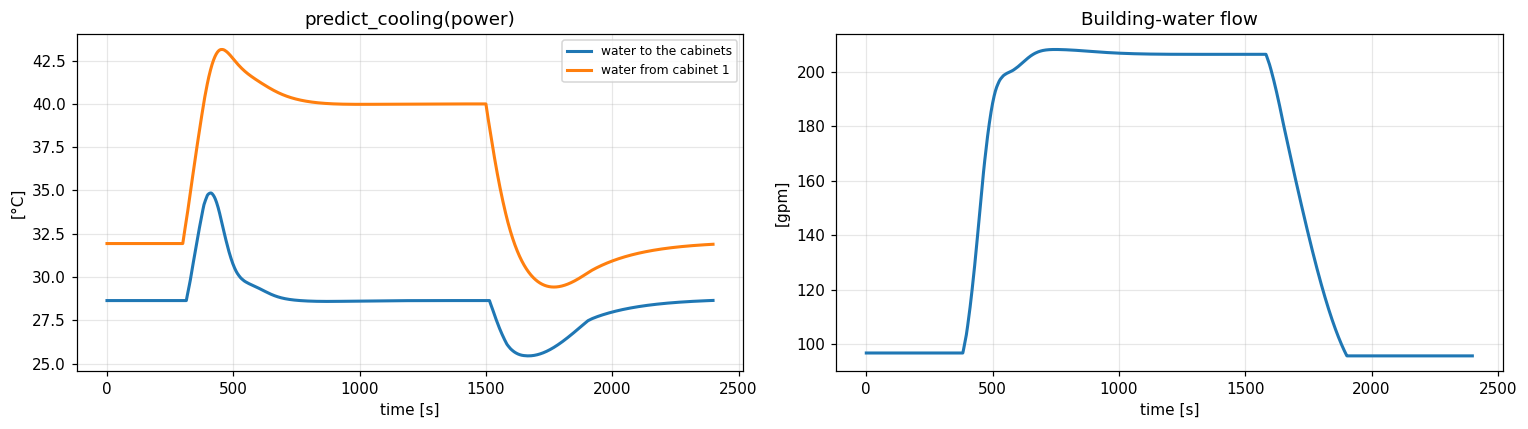

In [11]:
# Check 1: it should match the full model, and the real measurements, on the run it was fitted to.
out = predict_cooling(AC_M / 1e3, facility_water_C=PIT0)
late = t_cg > 300
print(f"against measurements after t = 300 s: supply {rms(out.supply_C[late] - LIT_M[late]):.2f} °C, outlet 1 {rms(out.outlet_1_C[late] - col('LOT_C1')[late]):.2f} °C, "
      f"flow {rms(out.facility_gpm[late] - PLF_M[late]):.1f} gpm, facility out {rms(out.facility_out_C[late] - col('CDU_POT')[late]):.2f} °C")
same_inputs = fm.run_cooling(M, AC_M, PIT0)
print(f"against the full model with the same inputs: supply differs by at most {np.abs(out.supply_C.to_numpy() - same_inputs['LIT']).max():.3f} °C")

# Check 2: holding one steady power should settle at the same numbers as the steady full-power run above
print(predict_cooling(330).tail(1).round(2).to_string())

# How simple it is to use: a job that starts after 5 minutes and runs for 20
power = np.r_[np.full(300, 90.0), np.full(1200, 330.0), np.full(900, 90.0)]
result = predict_cooling(power)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(result.supply_C, color=MAIN_C, lw=2, label='water to the cabinets'); ax[0].plot(result.outlet_1_C, color=CMP_C, lw=2, label='water from cabinet 1')
ax[0].set(xlabel='time [s]', ylabel='[°C]', title='predict_cooling(power)'); ax[0].legend(fontsize=8)
ax[1].plot(result.facility_gpm, color=MAIN_C, lw=2); ax[1].set(xlabel='time [s]', ylabel='[gpm]', title='Building-water flow')
fig.tight_layout(); fig.savefig(FIG / 'stress_predict_cooling.png', bbox_inches='tight')

**What the checks say.** On the real run, after the first 300 s, the function is within 0.40 °C on the supply, 0.48 °C on cabinet 1's outlet, 0.56 °C on the facility water, and 6.2 gpm on flow. It also matches the full model exactly when given the same inputs. The first 300 s aren't scored, because the function starts settled, while the real run began during the cool-down of an earlier job.

**Limits of the function.** It was fitted to one run of one cooling group in February, so another group, or the facility's summer conditions, could differ. It predicts the water, not the chip; for the chip, use `run_workload` or `fm.junction_response`.

## References

1. V. Vasudevan, X. Fan, "An acceleration model for lead-free (SAC) solder joint reliability under thermal cycling," *ECTC*, 2008. [PDF](https://www.lamar.edu/engineering/_files/documents/mechanical/dr.-fan-publications/2008/Fan%202008_13%20ECTC_3.pdf). Source of $n$ = 2.65, $m$ = 0.136, $E_a/k$ = 2185 K. The values 4 and 6 are what-if values I chose.
2. Copper electromigration activation energies near 0.9 eV: e.g. [Kinetics of electromigration damage in copper films](https://resolve.cambridge.org/core/journals/mrs-online-proceedings-library-archive/article/kinetics-of-electromigration-damage-in-copper-films-studied-by-isothermal-resistance-change-analysis/29B18FC814619401D4D1536EA94C9C61). Reported values vary with structure (about 0.8–1.1 eV).
3. Fraunhofer ENAS, [HPC package warpage and TIM pump-out presentation](https://www.enas.fraunhofer.de/content/dam/enas/Dokumente/Deutsch/News_Events/ChemnitzerSeminare/seminar_41_t-z_2025/2025-02-14_3-2%20BerlinerNanotest_AboRas.pdf), 2025. Silicon ~2.5 and organic substrate 10–20 ppm/K; larger dies warp more, loading the paste.
4. Mackie, ["Thermal Interface Materials," IEEE EPS Thermal Mechanical TC](https://eps.ieee.org/images/files/ThMech_TC_article_Thermal_Interface_Materials_-_Mackie_-_IEEE_EPS_Final_Copy.pdf). How mismatch and die shape load paste layers.
5. G. Ostrouchov et al., "GPU Lifetimes on Titan Supercomputer: Survival Analysis and Reliability," *SC20*. [Details](https://ornl.gov/publication/gpu-lifetimes-titan-supercomputer-survival-analysis-and-reliability). More than 100 000 GPU-years; reliability tied to heat dissipation, cooling layout and scheduling. It did not isolate thermal cycling.
6. Z. Sun et al., "Energy dataset of Frontier supercomputer for waste heat recovery," *Scientific Data* 11:1077, 2024. [doi:10.1038/s41597-024-03913-w](https://doi.org/10.1038/s41597-024-03913-w)
7. Jadhav & Liu, "Digital Twin-Based Cooling System Optimization for Data Center," [arXiv:2603.01198](https://arxiv.org/html/2603.01198), 2026. Facility supply range, ~12 to ~29 °C.
8. Electronics Cooling, [Design considerations for high-performance processor liquid-cooled cold plates](https://www.electronics-cooling.com/2011/12/technical-brief-design-considerations-for-high-performance-processor-liquid-cooled-cold-plates/), 2011. In laminar flow, velocity has little effect on the heat-transfer coefficient.

The cooling-group and junction fits, and their sources (ExaDigiT and others), are in `frontier_cooling_group.ipynb`.